# FIFA World Cup 2022: Team Performance Analysis

**What separates successful teams from unsuccessful ones at the 2022 World Cup: possession, passing, line-breaking, shooting, or discipline?**

## 1. Project Overview

This project analyses match-level team statistics from all 64 matches of the FIFA World Cup 2022 (128 team-match rows, one per team per match). It began as a classroom exercise on grouping by team and z-normalisation and has been extended into a question-driven analysis:

1. **Data quality:** is the data trustworthy, and what has to be corrected before analysis?
2. **Team performance:** who scored, conceded and qualified, and how do the group standings reconcile with the data?
3. **Style vs results:** do possession, passing volume, line-breaking and shot volume translate into goals and wins?
4. **Efficiency:** which teams scored more (or fewer) goals than their shot volume suggests?
5. **Discipline:** who was booked most, and what goes with it?
6. **Within-team variation (z-normalisation):** which matches were unusual *for the team that played them*, and do relationships hold within teams?
7. **Winners vs losers:** in the same match, which statistics actually differ between the two sides?

**Skills demonstrated:** data validation and cleaning, feature engineering (opponent join, stage, efficiency ratios), `groupby` / named aggregation, group-wise z-normalisation with `apply`, correlation and non-parametric tests (Spearman, Mann-Whitney, Wilcoxon), multiple-testing awareness, and communication through charts.

> **Caveat:** this is observational data from a single tournament, with only 3 to 7 matches per team. Findings describe associations in this sample and are not causal claims.

### Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 50)

RESULT_COLORS = {"Win": "#2e7d32", "Draw": "#9e9e9e", "Loss": "#c62828"}
STAGE_ORDER = ["Group stage", "Round of 16", "Quarter-final", "Semi-final", "Third place", "Final"]

## 2. Dataset Overview

The loader reads a local copy of the CSV if one is next to the notebook and otherwise falls back to the published Google Sheet used in the original exercise.

In [2]:
DATA_URL = ("https://docs.google.com/spreadsheets/d/e/2PACX-1vT3D_x_4DS6d51LKJ7ze1sxT5WpV5uiSVOFYHLwBiGru6vFyVv5h5-83AwFjxWYiWfCDjDAaarHAV-k/pub?gid=0&single=true&output=csv")
LOCAL_FILES = ["Fifa Worldcup 2022 - Sheet1.csv", "Fifa_Worldcup_2022_-_Sheet1.csv"]


def load_first_available(local_files, url):
    """Read a local copy of the CSV if present, otherwise the published Google Sheet."""
    for name in local_files:
        if Path(name).exists():
            return pd.read_csv(name), name
    return pd.read_csv(url), url


raw_df, source_used = load_first_available(LOCAL_FILES, DATA_URL)
raw_df = raw_df.loc[:, ~raw_df.columns.str.startswith("Unnamed")]   # drop a stray index column if the export has one
print(f"Loaded from: {source_used}")
print(f"Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")

Loaded from: Fifa_Worldcup_2022_-_Sheet1.csv
Shape: 128 rows x 38 columns


In [3]:
print("Column types:", raw_df.dtypes.astype(str).value_counts().to_dict())
print("Teams:", raw_df["Team"].nunique(), "| Matches:", raw_df["Match No."].nunique(),
      "| Rows per match:", raw_df.groupby("Match No.").size().unique().tolist())
raw_df.head(3).T

Column types: {'int64': 35, 'str': 3}
Teams: 32 | Matches: 64 | Rows per match: [2]


,0,1,2
Sl. No,1,2,3
Match No.,1,1,2
Team,Qatar,Ecuador,England
Against,Ecuador,Qatar,Iran
Group,A,A,B
Goal,0,2,6
Possession (%),40,46,69
Inside Penalty Area,0,2,6
Outside Penalty Area,0,0,0
Assists,0,1,6


Each match appears twice: once from each team's perspective (`Team` vs `Against`). The 35 numeric columns fall into these groups (labels as they appear in the file; the file has no data dictionary):

| Group | Columns |
|---|---|
| Identifiers | `Sl. No`, `Match No.` (1 to 64), `Team`, `Against`, `Group` (the team's group letter) |
| Result | `Goal`, `Pts`, `Penalties Scored` |
| Possession and passing | `Possession (%)`, `Passes`, `Passes Completed`, `Crosses`, `Crosses Completed`, `Receptions MD`, `Receptions D` |
| Progression | `Attempted / Completed Line Breaks`, `Attempted / Completed Defensive Line Breaks` |
| Shooting | `Total Attempts`, `On Target`, `Off Target`, `Target in Penalty`, `Target from Outside`, `Inside / Outside Penalty Area` (goals by location), `Assists` |
| Attacking channels | `Left`, `Left Inside`, `Central`, `Right Inside`, `Right Channel` |
| Set pieces | `Corners`, `Free Kicks`, `Offsides` |
| Discipline | `Yellow Cards`, `Red Cards`, `Fouls Against` |

Note that there is no explicit stage, opponent-goals or match-outcome column. These are derived below, since most of the interesting questions (goal difference, wins, qualification) depend on them.

## 3. Data Quality & Preparation

### 3.1 Completeness, duplicates and types

In [4]:
quality_summary = pd.Series({
    "Missing values (all cells)": int(raw_df.isna().sum().sum()),
    "Fully duplicated rows": int(raw_df.duplicated().sum()),
    "Duplicated (Match No., Team) pairs": int(raw_df.duplicated(["Match No.", "Team"]).sum()),
    "Non-numeric columns": ", ".join(raw_df.select_dtypes(exclude="number").columns),
    "Teams with more than one Group value": int(raw_df.groupby("Team")["Group"].nunique().gt(1).sum()),
})
quality_summary.to_frame("Result")

,Result
Missing values (all cells),0
Fully duplicated rows,0
"Duplicated (Match No., Team) pairs",0
Non-numeric columns,"Team, Against, Group"
Teams with more than one Group value,0


**Finding:** the file is structurally clean. There are no missing values, no duplicate rows, every column that should be numeric is numeric, and each team belongs to exactly one group. The checks below look for problems in the *values*.

### 3.2 Categorical consistency: opponent names
Every opponent listed in `Against` should also appear as a `Team`.

In [5]:
# Every opponent named in "Against" should also appear as a "Team"
unknown_opponents = sorted(set(raw_df["Against"]) - set(raw_df["Team"]))
print("Opponent names that are not a Team:", unknown_opponents)

# Show the affected match: both rows of match 62
bad_match = raw_df.loc[raw_df["Against"].isin(unknown_opponents), "Match No."].iloc[0]
raw_df.loc[raw_df["Match No."] == bad_match, ["Match No.", "Team", "Against", "Group", "Goal", "Pts"]]

Opponent names that are not a Team: ['Fram']


,Match No.,Team,Against,Group,Goal,Pts
122,62,France,Morocco,D,2,3
123,62,Morocco,Fram,F,0,0


**Finding:** one typo. In match 62 (the semi-final) Morocco's row lists its opponent as "Fram", while the other row of the same match is France vs Morocco. It is corrected to "France" in the next step; otherwise the opponent's goals could not be joined for that match.

### 3.3 Building match context: stage, opponent goals, result
The original data has no stage, opponent-goals or outcome column, so these are derived. The stage comes from the match number using the standard 2022 schedule (48 group matches, 8 in the round of 16, 4 quarter-finals, 2 semi-finals, the third-place match and the final); the assertion checks that the number of teams per stage is what that schedule implies.

In [6]:
fifa_df = raw_df.copy()

# 1. Fix the misspelt opponent: match 62 is Morocco vs France (the other row of the match is France vs Morocco)
fifa_df["Against"] = fifa_df["Against"].replace({"Fram": "France"})

# 2. Tournament stage from the match number (standard 2022 schedule: 48 group matches, then 8 + 4 + 2 + 1 + 1)
fifa_df["Stage"] = pd.cut(fifa_df["Match No."], bins=[0, 48, 56, 60, 62, 63, 64],
                          labels=STAGE_ORDER).astype(str)

# 3. Opponent's goals: join each row to the opposite row of the same match
opponent_goals = (fifa_df[["Match No.", "Team", "Goal"]]
                  .rename(columns={"Team": "Against", "Goal": "Goals Against"}))
fifa_df = fifa_df.merge(opponent_goals, on=["Match No.", "Against"], how="left", validate="one_to_one")

# 4. Match outcome from goals (a penalty shoot-out is therefore a "Draw")
fifa_df["Goal Difference"] = fifa_df["Goal"] - fifa_df["Goals Against"]
fifa_df["Result"] = np.select([fifa_df["Goal Difference"] > 0, fifa_df["Goal Difference"] < 0],
                              ["Win", "Loss"], default="Draw")

# 5. Points earned in the group stage, recomputed from goals
fifa_df["Group Points"] = np.where(fifa_df["Stage"] == "Group stage",
                                   fifa_df["Result"].map({"Win": 3, "Draw": 1, "Loss": 0}), np.nan)

# 6. Knockout draws must have been settled by extra time and a shoot-out
fifa_df["Went to Shoot-out"] = (fifa_df["Stage"] != "Group stage") & (fifa_df["Result"] == "Draw")

# Sanity checks on the reconstruction
stage_teams = fifa_df.groupby("Stage")["Team"].nunique().reindex(STAGE_ORDER)
assert stage_teams.tolist() == [32, 16, 8, 4, 2, 2], stage_teams
assert fifa_df["Goals Against"].notna().all()
assert fifa_df.groupby("Match No.")["Goal"].sum().sum() == fifa_df["Goal"].sum()
print("Teams per stage:", stage_teams.to_dict())
print("Total goals:", fifa_df["Goal"].sum(), "in", fifa_df["Match No."].nunique(), "matches")
print("Shoot-out matches:", fifa_df.loc[fifa_df["Went to Shoot-out"], "Match No."].nunique())
fifa_df["Result"].value_counts().to_frame("Team-matches").T

Teams per stage: {'Group stage': 32, 'Round of 16': 16, 'Quarter-final': 8, 'Semi-final': 4, 'Third place': 2, 'Final': 2}
Total goals: 172 in 64 matches
Shoot-out matches: 5


Result,Loss,Win,Draw
Team-matches,49,49,30


**Decisions:** the result is decided on goals scored, so a match settled by a penalty shoot-out counts as a draw (`Result`). `Group Points` is recomputed from the score for group matches only. A drawn knockout match must have gone to extra time and a shoot-out, which gives the `Went to Shoot-out` flag (5 matches). This assumes no knockout match was decided by an extra-time goal; that is my understanding of the 2022 tournament and cannot be checked from this file.

### 3.4 Extra time: a systematic distortion in the counts
Statistics for the 5 shoot-out matches cover roughly 120 minutes instead of 90, which inflates every count.

In [7]:
# Extra time inflates counts: how big is the effect on pass volume?
print(fifa_df.groupby("Went to Shoot-out")[["Passes", "Total Attempts", "Yellow Cards"]].mean().round(1)
      .rename(index={False: "Settled in 90 minutes or less", True: "Extra time + shoot-out"}))

                               Passes  Total Attempts  Yellow Cards
Went to Shoot-out                                                  
Settled in 90 minutes or less  490.60           11.10          1.60
Extra time + shoot-out         647.80           12.90          2.80


**Finding:** team-matches that went to extra time show about 32% more passes (648 vs 491 on average) and higher yellow-card counts. These matches are kept (they are real matches) but the flag is used as a robustness check where counts matter.

### 3.5 Logical consistency
Completed actions cannot exceed attempted ones, shots should split cleanly into in-box and outside-box, and points should follow the score.

In [8]:
consistency_checks = pd.Series({
    "Passes Completed > Passes": (fifa_df["Passes Completed"] > fifa_df["Passes"]).sum(),
    "Crosses Completed > Crosses": (fifa_df["Crosses Completed"] > fifa_df["Crosses"]).sum(),
    "Completed Line Breaks > Attempted": (fifa_df["Completed Line Breaks"] > fifa_df["Attempted Line Breaks"]).sum(),
    "Completed Defensive Line Breaks > Attempted": (fifa_df["Completed Defensive Line Breaks"] > fifa_df["Attempted Defensive Line Breaks"]).sum(),
    "Total Attempts != in-box + outside-box attempts": (fifa_df["Total Attempts"] != fifa_df["Target in Penalty"] + fifa_df["Target from Outside"]).sum(),
    "Goal != goals from inside + outside the box": (fifa_df["Goal"] != fifa_df["Inside Penalty Area"] + fifa_df["Outside Penalty Area"]).sum(),
    "Goal > shots On Target": (fifa_df["Goal"] > fifa_df["On Target"]).sum(),
    "Group-stage Pts != Pts implied by the score": ((fifa_df["Stage"] == "Group stage") & (fifa_df["Pts"] != fifa_df["Group Points"])).sum(),
}).astype(int)
display(consistency_checks.to_frame("Rows flagged"))

flag_cols = ["Match No.", "Team", "Against", "Goal", "Goals Against", "Inside Penalty Area", "On Target", "Pts"]
flagged = fifa_df[(fifa_df["Goal"] != fifa_df["Inside Penalty Area"] + fifa_df["Outside Penalty Area"])
                  | ((fifa_df["Stage"] == "Group stage") & (fifa_df["Pts"] != fifa_df["Group Points"]))]
display(flagged[flag_cols])

# Possession is measured per team, so the two teams of a match should not sum to more than 100
possession_total = fifa_df.groupby("Match No.")["Possession (%)"].sum()
print(f"Combined possession per match: min {possession_total.min()}%, max {possession_total.max()}%")

# In knockout draws, Pts records the shoot-out winner (3) and loser (0)
print("Knockout draws, Pts values:", sorted(fifa_df.loc[fifa_df["Went to Shoot-out"], "Pts"].unique()))

,Rows flagged
Passes Completed > Passes,0
Crosses Completed > Crosses,0
Completed Line Breaks > Attempted,0
Completed Defensive Line Breaks > Attempted,0
Total Attempts != in-box + outside-box attempts,0
Goal != goals from inside + outside the box,3
Goal > shots On Target,1
Group-stage Pts != Pts implied by the score,1


,Match No.,Team,Against,Goal,Goals Against,Inside Penalty Area,On Target,Pts
32,17,Wales,Iran,0,2,0,3,1
82,42,Canada,Morocco,1,2,0,0,0
86,44,Costa Rica,Germany,2,4,1,5,0
99,50,Australia,Argentina,1,2,0,2,0


Combined possession per match: min 75%, max 92%
Knockout draws, Pts values: [np.int64(0), np.int64(3)]


**Findings**

- **Completed vs attempted, and shot splits:** no violations. `Total Attempts` equals in-box plus outside-box attempts in all 128 rows.
- **Wales v Iran (match 17):** Wales lost 0-2 but is recorded with `Pts = 1`. This is a data-entry error (Iran correctly has 3). The original `Pts` column is left untouched, and `Group Points` (recomputed from the score) is used for the group standings. Using the raw column would have given Wales 2 group points instead of 1.
- **Knockout draws:** `Pts` is 3 or 0 for the five shoot-out matches, i.e. it records the shoot-out winner and loser, so `Pts` is not used for knockout analysis.
- **Goals without a recorded penalty-area goal (3 rows) and one team with more goals than shots on target (Canada):** these fit own goals or a recording gap, but the file does not say. `Goal` is used as recorded.
- **Penalties Scored:** the only values of 3 to 5 occur in the five shoot-out matches, so this column mixes in-play penalties with shoot-out kicks and is not analysed.
- **Possession:** the two teams' possession shares sum to 75-92% per match, never above 100%. The remainder is presumably contested time, so possession is a share of total time rather than a split between the two sides.

### 3.6 Outliers
Values beyond 1.5 × IQR from the quartiles are counted for the main metrics.

In [9]:
def iqr_outlier_table(data, columns):
    """Count values beyond 1.5 x IQR from the quartiles for each column."""
    rows = []
    for col in columns:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        rows.append({"Metric": col,
                     "Below fence": int((data[col] < q1 - 1.5 * iqr).sum()),
                     "Above fence": int((data[col] > q3 + 1.5 * iqr).sum()),
                     "Median": data[col].median(), "Maximum": data[col].max()})
    return pd.DataFrame(rows).set_index("Metric")


screen_cols = ["Possession (%)", "Passes", "Attempted Line Breaks", "Completed Line Breaks", "Total Attempts",
               "On Target", "Yellow Cards", "Fouls Against", "Receptions D"]
display(iqr_outlier_table(fifa_df, screen_cols))
fifa_df.nlargest(3, "Receptions D")[["Match No.", "Team", "Against", "Receptions D", "Receptions MD"]]

,Below fence,Above fence,Median,Maximum
Metric,,,,
Possession (%),0,1,45.00,78
Passes,0,3,495.50,1070
Attempted Line Breaks,3,4,170.50,259
Completed Line Breaks,1,1,106.00,192
Total Attempts,0,5,10.00,32
On Target,0,1,4.00,13
Yellow Cards,0,13,2.00,8
Fouls Against,0,2,12.00,30
Receptions D,0,8,9.00,192


,Match No.,Team,Against,Receptions D,Receptions MD
18,10,Germany,Japan,192,145
19,10,Japan,Germany,79,43
77,39,Argentina,Poland,36,150


**Findings**

- **Genuine extremes, kept:** Spain's three matches with 1,050 to 1,070 passes are the only pass-count outliers, and yellow cards, shot attempts and line breaks show a handful of high values. These are real performances rather than errors.
- **Receptions D:** one value stands out on any reading. Germany's 192 in match 10 (with 79 for Japan in the same match) compares with a median of 9, and no other team-match outside that game exceeds 36. Its definition is also not given in the file, so `Receptions D` and `Receptions MD` are **excluded from the analysis**.

### 3.7 Derived efficiency metrics
Ratios are more comparable across matches than raw counts. A zero denominator gives `NaN` rather than infinity.

In [10]:
def pct(numerator, denominator):
    """Percentage that returns NaN (not inf) when the denominator is zero."""
    return numerator / denominator.replace(0, np.nan) * 100


fifa_df["Pass Accuracy (%)"] = pct(fifa_df["Passes Completed"], fifa_df["Passes"])
fifa_df["Line Break Success (%)"] = pct(fifa_df["Completed Line Breaks"], fifa_df["Attempted Line Breaks"])
fifa_df["Shot Accuracy (%)"] = pct(fifa_df["On Target"], fifa_df["Total Attempts"])
fifa_df["Cross Accuracy (%)"] = pct(fifa_df["Crosses Completed"], fifa_df["Crosses"])

print("Rows with no attempts (shot accuracy undefined):", fifa_df["Shot Accuracy (%)"].isna().sum())
fifa_df[["Pass Accuracy (%)", "Line Break Success (%)", "Shot Accuracy (%)", "Cross Accuracy (%)"]].describe().T

Rows with no attempts (shot accuracy undefined): 1


,count,mean,std,min,25%,50%,75%,max
Pass Accuracy (%),128.00,84.23,5.86,65.38,81.27,85.50,88.33,94.43
Line Break Success (%),128.00,63.94,9.18,33.93,57.33,63.84,70.66,89.36
Shot Accuracy (%),127.00,35.26,16.91,0.00,26.67,34.38,42.86,100.00
Cross Accuracy (%),128.00,25.03,11.54,0.00,17.10,25.00,30.77,62.50


**Summary of data-quality decisions**

| Issue | Action |
|---|---|
| No missing values, duplicates or type problems | None needed |
| "Fram" in `Against` (match 62) | Corrected to France |
| Wales v Iran `Pts` error | `Pts` kept as is; `Group Points` recomputed from the score |
| Knockout `Pts` records shoot-out winners | `Pts` not used for knockout rounds |
| Extra-time matches inflate counts | Flagged (`Went to Shoot-out`) and used as a robustness check |
| `Receptions D` extreme value, undefined columns | Excluded |
| `Penalties Scored` includes shoot-out kicks | Excluded |
| Different numbers of matches per team (3 to 7) | Per-match averages and rates; small-sample caveats throughout |

## 4. Exploratory Data Analysis

### 4.1 What does a typical team performance look like?

,count,mean,std,min,25%,50%,75%,max
Goal,128.00,1.34,1.34,0.00,0.00,1.00,2.00,7.00
Possession (%),128.00,43.48,11.44,14.00,35.00,45.00,51.00,78.00
Passes,128.00,502.86,160.16,225.00,398.25,495.50,589.50,"1,070.00"
Pass Accuracy (%),128.00,84.23,5.86,65.38,81.27,85.50,88.33,94.43
Total Attempts,128.00,11.26,5.41,0.00,7.75,10.00,14.00,32.00
Yellow Cards,128.00,1.73,1.51,0.00,1.00,2.00,2.00,8.00


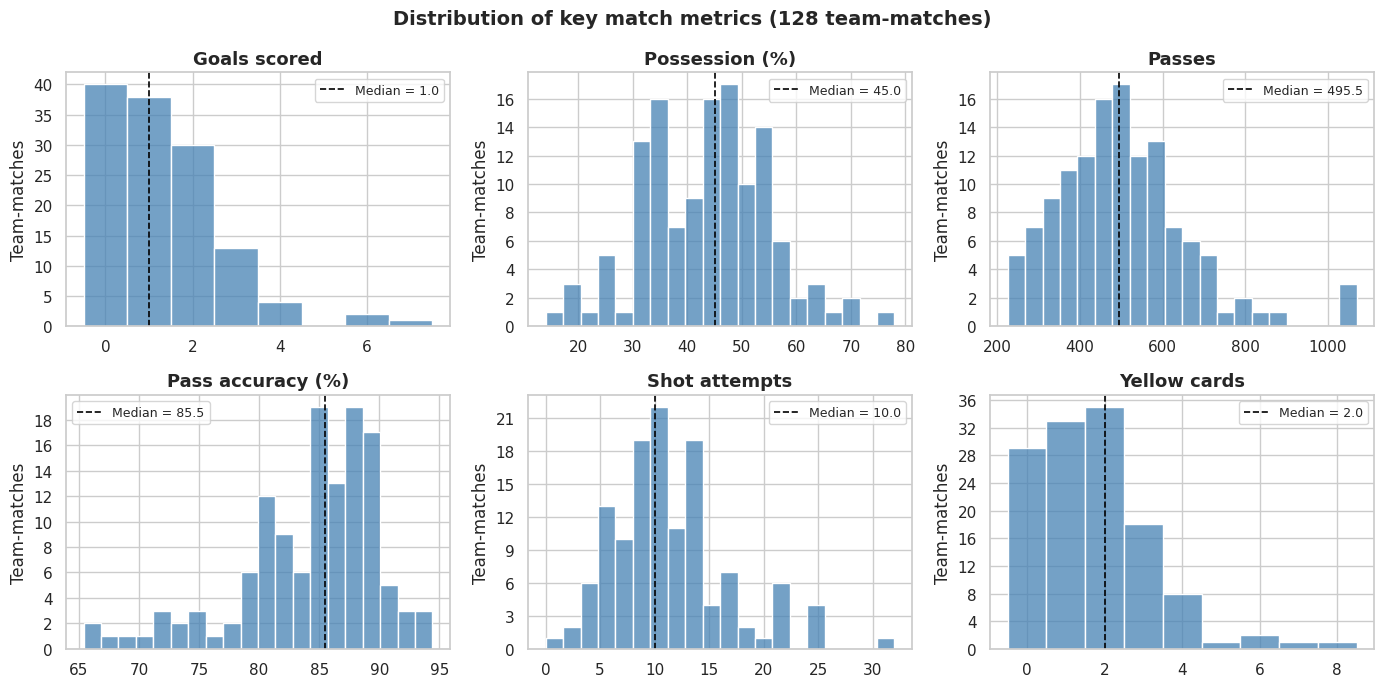

In [11]:
eda_metrics = {
    "Goal": "Goals scored", "Possession (%)": "Possession (%)", "Passes": "Passes",
    "Pass Accuracy (%)": "Pass accuracy (%)", "Total Attempts": "Shot attempts", "Yellow Cards": "Yellow cards",
}
display(fifa_df[list(eda_metrics)].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, label) in zip(axes.ravel(), eda_metrics.items()):
    hist_kwargs = {"discrete": True} if col in ["Goal", "Yellow Cards"] else {"bins": 20}
    sns.histplot(fifa_df[col], color="steelblue", ax=ax, **hist_kwargs)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.axvline(fifa_df[col].median(), color="black", ls="--", lw=1.2, label=f"Median = {fifa_df[col].median():,.1f}")
    ax.set(title=label, xlabel="", ylabel="Team-matches")
    ax.legend(fontsize=9)
fig.suptitle("Distribution of key match metrics (128 team-matches)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**What the data shows:** the tournament produced 172 goals in 64 matches (2.69 per match). A team scored a median of 1 goal, and 40 of the 128 team-matches (31%) were scoreless; the maximum was 7 (Spain v Costa Rica). Median possession is 45%, below 50% because of the contested share noted above. Pass counts are centred around 496 (middle half 398 to 590) with a long right tail from Spain, and median pass accuracy is 85.5% with a tail of lower values. The typical team took 10 shots, and yellow cards are concentrated at 0 to 2 with a right tail up to 8.

**Interpretation:** goals, cards and shots are discrete and right-skewed, so medians and rank-based statistics (Spearman) are used in the analysis rather than means and Pearson correlation. Pass counts differ hugely between teams' styles, which sets up the within-team comparison later.

### 4.2 How do the metrics relate to each other?
Spearman correlations across all 128 team-matches.

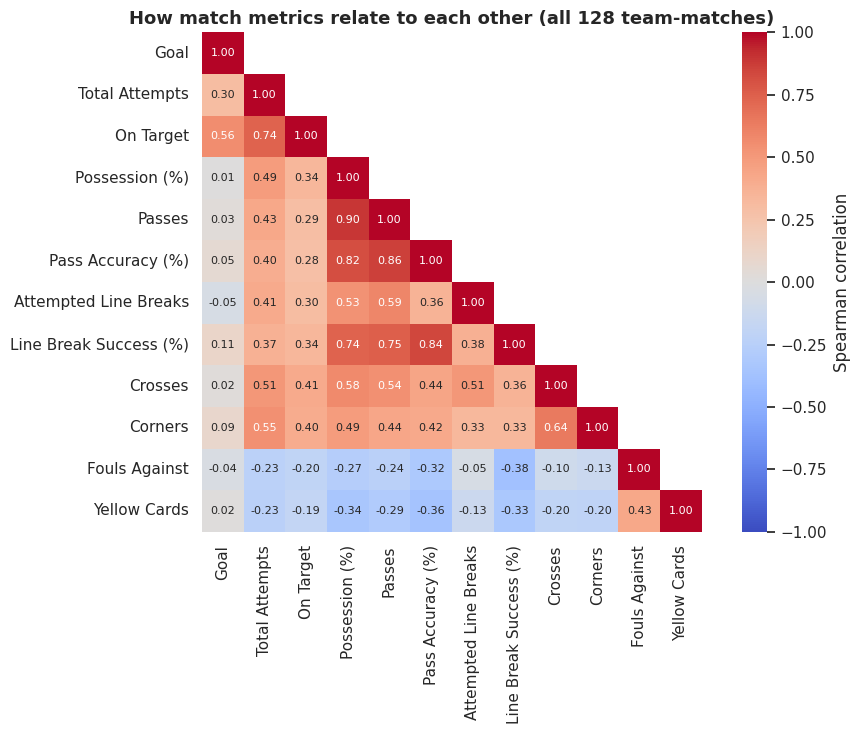

In [12]:
corr_metrics = ["Goal", "Total Attempts", "On Target", "Possession (%)", "Passes", "Pass Accuracy (%)",
                "Attempted Line Breaks", "Line Break Success (%)", "Crosses", "Corners", "Fouls Against", "Yellow Cards"]
corr = fifa_df[corr_metrics].corr(method="spearman")

plt.figure(figsize=(10, 7.5))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"label": "Spearman correlation"}, annot_kws={"size": 8})
plt.title("How match metrics relate to each other (all 128 team-matches)")
plt.grid(False)
plt.tight_layout()
plt.show()

**What the data shows:** the "style" metrics move together: possession and passes (0.90), passes and pass accuracy (0.86), and line-break success and pass accuracy (0.84). Shot attempts and on-target shots rise with possession and passing (0.28 to 0.49). Goals behave differently: they relate to shots on target (0.56) and, more weakly, to total attempts (0.30), while every other metric has |ρ| ≤ 0.11 with goals. Yellow cards go with fouls (0.43) and fall as possession, passing and accuracy rise (-0.29 to -0.36).

**Interpretation:** there is one strong "ball control" dimension (possession, passing, accuracy, line-break success) and it is barely related to scoring in a given match. Scoring links to shooting quality. The rest of the analysis tests this reading from several angles.

## 5. Team Analysis

### 5.1 Team profiles: the original `groupby("Team")` aggregation
The first step of the original exercise, kept and extended: per-team minimum and maximum passes, yellow-card statistics, attempted line-break spread and average possession. The chart then shows how much a team's own pass count moves from match to match.

,matches,passes_min,passes_max,yellow_min,yellow_max,yellow_mean,line_breaks_min,line_breaks_max,line_breaks_std,possession_mean
Team,,,,,,,,,,
Argentina,7,408,862,0,8,2.29,141,249,38.77,49.29
Australia,4,286,466,0,3,1.75,133,171,17.68,31.25
Belgium,3,512,685,1,3,1.67,167,195,14.42,49.00
Brazil,5,548,695,0,3,1.20,164,193,10.69,50.40
Cameroon,3,295,500,1,5,2.67,144,182,19.86,38.33
Canada,3,448,536,2,4,2.67,102,176,37.75,44.33
Costa Rica,3,231,454,1,3,2.00,86,154,38.97,27.33
Croatia,7,461,724,0,2,1.14,97,259,54.50,47.43
Denmark,3,537,650,1,2,1.67,173,241,34.00,51.33


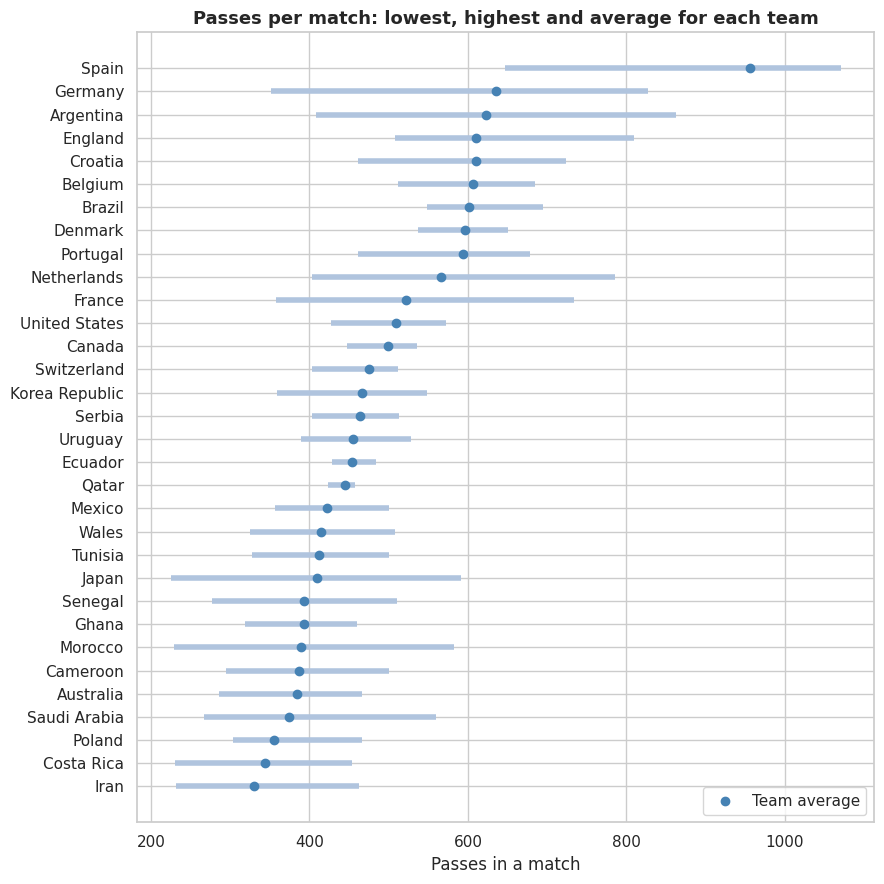

In [13]:
# Team-level grouping (kept from the original analysis)
teams = fifa_df.groupby("Team")

team_profile = teams.agg(
    matches=("Match No.", "count"),
    passes_min=("Passes", "min"), passes_max=("Passes", "max"), passes_mean=("Passes", "mean"),
    yellow_min=("Yellow Cards", "min"), yellow_max=("Yellow Cards", "max"), yellow_mean=("Yellow Cards", "mean"),
    line_breaks_min=("Attempted Line Breaks", "min"), line_breaks_max=("Attempted Line Breaks", "max"),
    line_breaks_std=("Attempted Line Breaks", "std"),
    possession_mean=("Possession (%)", "mean"),
)
display(team_profile.drop(columns="passes_mean").round(2))

# How much does a team's pass count move from match to match?
plot_df = team_profile.sort_values("passes_mean")
fig, ax = plt.subplots(figsize=(9, 9))
ax.hlines(plot_df.index, plot_df["passes_min"], plot_df["passes_max"], color="lightsteelblue", lw=4)
ax.scatter(plot_df["passes_mean"], plot_df.index, color="steelblue", zorder=3, label="Team average")
ax.set(title="Passes per match: lowest, highest and average for each team", xlabel="Passes in a match", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What the data shows**

- **Passing volume varies as much within teams as between them.** Germany ranged from 352 to 827 passes and Argentina from 408 to 862; Japan (225 to 591) and Morocco (229 to 583) also swung by more than 350. Spain sits in a class of its own, never below 647 and reaching 1,070.
- **Possession:** Spain averaged the most (67.0%) and Costa Rica the least (27.3%).
- **Discipline:** Saudi Arabia (4.67 yellow cards per match) and Serbia (4.00, with 7 in one match) were booked most; England (0.20) and Spain (0.50) least. Argentina's 8 yellow cards in the quarter-final against the Netherlands is the highest single-match figure.
- **Line breaks:** Iran (standard deviation 77.5), Japan (64.1) and Germany (56.6) had the most variable attempted line-break counts.

**Interpretation:** a raw count is hard to judge without knowing the team. 600 passes is ordinary for Argentina but well above anything Iran managed. This is the motivation for normalising within teams (section 6). With only 3 to 7 matches each, a single unusual match moves a team's minimum, maximum and standard deviation a lot.

### 5.2 Q1. Who scored and conceded most?
Goal difference per match is used rather than the total, because teams played between 3 and 7 matches.

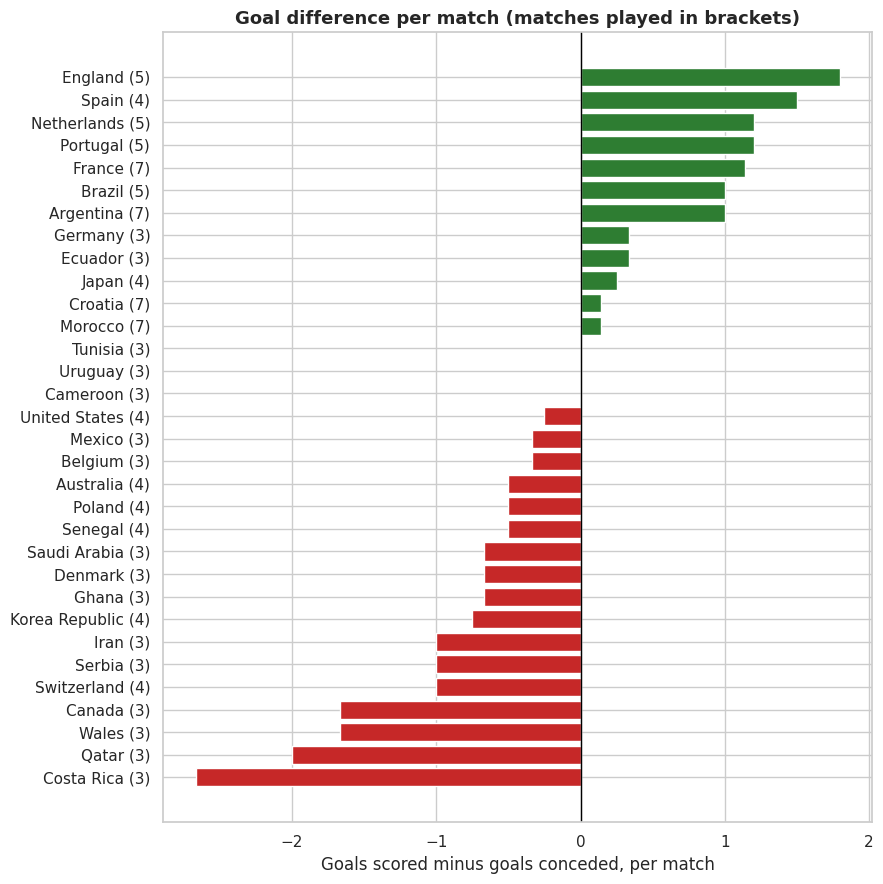

,matches,goals_for,goals_against,goal_diff,goals_for_pm,goals_against_pm
Team,,,,,,
England,5,13,4,9,2.60,0.80
Spain,4,9,3,6,2.25,0.75
Netherlands,5,10,4,6,2.00,0.80
Portugal,5,12,6,6,2.40,1.20
France,7,16,8,8,2.29,1.14
Argentina,7,15,8,7,2.14,1.14
Brazil,5,8,3,5,1.60,0.60
Germany,3,6,5,1,2.00,1.67


In [14]:
team_df = teams.agg(
    matches=("Match No.", "count"),
    goals_for=("Goal", "sum"), goals_against=("Goals Against", "sum"),
    possession=("Possession (%)", "mean"), passes=("Passes", "mean"),
    passes_sum=("Passes", "sum"), passes_completed_sum=("Passes Completed", "sum"),
    shots=("Total Attempts", "mean"), shots_sum=("Total Attempts", "sum"), on_target_sum=("On Target", "sum"),
    line_breaks=("Attempted Line Breaks", "mean"), line_breaks_sum=("Attempted Line Breaks", "sum"),
    line_breaks_completed_sum=("Completed Line Breaks", "sum"),
    yellow_cards=("Yellow Cards", "mean"), fouls=("Fouls Against", "mean"),
)
team_df["goal_diff"] = team_df["goals_for"] - team_df["goals_against"]
team_df["goals_for_pm"] = team_df["goals_for"] / team_df["matches"]
team_df["goals_against_pm"] = team_df["goals_against"] / team_df["matches"]
team_df["goal_diff_pm"] = team_df["goal_diff"] / team_df["matches"]
team_df["pass_accuracy"] = team_df["passes_completed_sum"] / team_df["passes_sum"] * 100
team_df["line_break_success"] = team_df["line_breaks_completed_sum"] / team_df["line_breaks_sum"] * 100
team_df["shot_accuracy"] = team_df["on_target_sum"] / team_df["shots_sum"] * 100

ranked = team_df.sort_values("goal_diff_pm")
fig, ax = plt.subplots(figsize=(9, 9))
colors = np.where(ranked["goal_diff_pm"] >= 0, "#2e7d32", "#c62828")
ax.barh([f"{t} ({m})" for t, m in zip(ranked.index, ranked["matches"])], ranked["goal_diff_pm"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set(title="Goal difference per match (matches played in brackets)", xlabel="Goals scored minus goals conceded, per match")
plt.tight_layout()
plt.show()

team_df.sort_values("goal_diff_pm", ascending=False)[["matches", "goals_for", "goals_against", "goal_diff",
                                                      "goals_for_pm", "goals_against_pm"]].head(8)

**What the data shows:** England had the best goal difference per match (+1.80, +9 in total) ahead of Spain (+1.50), then the Netherlands and Portugal (both +1.20). France scored the most goals (16) and Argentina 15, but they rank only 5th (+1.14) and 7th (+1.00) by goal difference per match. At the bottom, Costa Rica (-2.67, 11 conceded in 3 matches), Qatar (-2.00), and Wales and Canada (-1.67) were the weakest.

**Interpretation:** the two finalists were not the most dominant sides on goal difference; they also played more matches (7 each), and their tallies include extra-time matches. **Caveat:** three-match samples for 16 teams make these rates volatile.

### 5.3 Q2. Group standings and who qualified
Group points are recomputed from the score, ranked by points, then goal difference, then goals scored. The result is checked against the teams that actually appear in the round of 16.

In [15]:
group_matches = fifa_df[fifa_df["Stage"] == "Group stage"]
standings = (group_matches.groupby(["Group", "Team"])
             .agg(Played=("Match No.", "count"), Points=("Group Points", "sum"),
                  GF=("Goal", "sum"), GA=("Goals Against", "sum"))
             .reset_index())
standings["Points"] = standings["Points"].astype(int)
standings["GD"] = standings["GF"] - standings["GA"]
standings = standings.sort_values(["Group", "Points", "GD", "GF"], ascending=[True, False, False, False])
standings["Rank"] = standings.groupby("Group").cumcount() + 1
round_of_16_teams = set(fifa_df.loc[fifa_df["Stage"] == "Round of 16", "Team"])
standings["Qualified"] = standings["Team"].isin(round_of_16_teams)

display(standings.set_index(["Group", "Rank"]))
print("Qualified teams by group rank:")
print(pd.crosstab(standings["Rank"], standings["Qualified"]).to_string())
four_points = standings[standings["Points"] == 4]
print(f"\nTeams that finished on exactly 4 points: {len(four_points)}, of which {four_points['Qualified'].sum()} qualified "
      f"({', '.join(four_points.loc[four_points['Qualified'], 'Team'])})")

# What did qualifying teams do differently in the group stage? (per-match team averages, 16 v 16)
gs_team = (group_matches.groupby("Team")[["Possession (%)", "Passes", "Pass Accuracy (%)", "Total Attempts",
                                          "On Target", "Attempted Line Breaks", "Yellow Cards", "Fouls Against"]]
           .mean())
gs_team["Qualified"] = gs_team.index.isin(round_of_16_teams)
comparison = gs_team.groupby("Qualified").mean().T.rename(columns={False: "Eliminated", True: "Qualified"})
comparison["Difference"] = comparison["Qualified"] - comparison["Eliminated"]
comparison["p (Mann-Whitney)"] = [
    stats.mannwhitneyu(gs_team.loc[gs_team["Qualified"], m], gs_team.loc[~gs_team["Qualified"], m]).pvalue
    for m in comparison.index]
comparison.style.format("{:.3f}")

Team  Played  Points  GF  GA  GD  Qualified
Group Rank                                                       
A     1        Netherlands       3       7   5   1   4       True
      2            Senegal       3       6   5   4   1       True
      3            Ecuador       3       4   4   3   1      False
      4              Qatar       3       0   1   7  -6      False
B     1            England       3       7   9   2   7       True
      2      United States       3       5   2   1   1       True
      3               Iran       3       3   4   7  -3      False
      4              Wales       3       1   1   6  -5      False
C     1          Argentina       3       6   5   2   3       True
      2             Poland       3       4   2   2   0       True
      3             Mexico       3       4   2   3  -1      False
      4       Saudi Arabia       3       3   3   5  -2      False
D     1             France       3       6   6   3   3       True
      2          Australia       3       6   3   4  -1       True
      3            Tunisia       3       4   1   1   0      False
      4            Denmark       3       1   1   3  -2      False
E     1              Japan       3       6   4   3   1       True
      2              Spain       3       4   9   3   6       True
      3            Germany       3       4   6   5   1      False
      4         Costa Rica       3       3   3  11  -8      False
F     1            Morocco       3       7   4   1   3       True
      2            Croatia       3       5   4   1   3       True
      3            Belgium       3       4   1   2  -1      False
      4             Canada       3       0   2   7  -5      False
G     1             Brazil       3       6   3   1   2       True
      2        Switzerland       3       6   4   3   1       True
      3           Cameroon       3       4   4   4   0      False
      4             Serbia       3       1   5   8  -3      False
H     1           Portugal       3       6   6   4   2       True
      2     Korea Republic       3       4   4   4   0       True
      3            Uruguay       3       4   2   2   0      False
      4              Ghana       3       3   5   7  -2      False

Qualified teams by group rank:
Qualified  False  True 
Rank                   
1              0      8
2              0      8
3              8      0
4              8      0

Teams that finished on exactly 4 points: 10, of which 3 qualified (Poland, Spain, Korea Republic)


Qualified,Eliminated,Qualified,Difference,p (Mann-Whitney)
Possession (%),41.292,45.188,3.896,0.213
Passes,451.958,524.646,72.688,0.258
Pass Accuracy (%),82.240,85.392,3.152,0.044
Total Attempts,10.542,11.417,0.875,0.407
On Target,3.542,4.167,0.625,0.273
Attempted Line Breaks,166.500,165.271,-1.229,0.925
Yellow Cards,2.271,1.208,-1.063,0.002
Fouls Against,12.229,11.438,-0.792,0.706


**What the data shows**

- **The recomputed table reproduces qualification exactly:** all 16 teams ranked first or second qualified, and all 16 ranked third or fourth went out, using only points, goal difference and goals scored.
- **4 points was a gamble:** 10 teams finished on exactly 4 points and only 3 qualified (Poland, Spain, Korea Republic); goal difference decided the rest.
- **What separated qualifiers from eliminated teams (16 v 16, group stage averages)?** Qualifiers were booked about half as often (1.21 vs 2.27 yellow cards per match, p = 0.002) and had higher pass accuracy (85.4% vs 82.2%, p = 0.044). Possession (+3.9 points), passes (+73), shots (+0.9) and on-target shots (+0.6) point the same way but are not distinguishable with 16 teams per side (p = 0.21 to 0.41); line-break attempts are identical (166.5 vs 165.3).

**Interpretation and caveats:** with 8 comparisons the conventional threshold shrinks to about 0.006 (Bonferroni), so only the yellow-card difference is convincing; pass accuracy is suggestive. Cards may partly reflect game state (teams that are ahead have less need to foul) rather than cause qualification, and each team played only three group matches.

### 5.4 Q3. Does possession win matches?

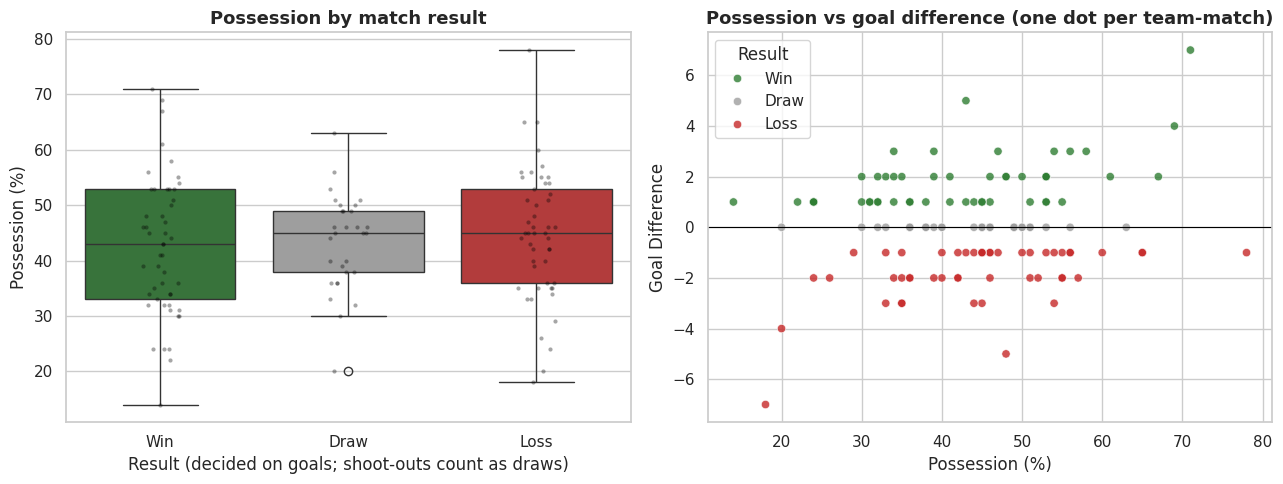

        count  mean  median
Result                     
Win        49 42.40   43.00
Draw       30 43.40   45.00
Loss       49 44.60   45.00

Spearman correlation, possession vs goal difference: rho = 0.03 (p = 0.71)
Results when a team had 60%+ possession: {'Win': 4, 'Loss': 4, 'Draw': 1}


,Match No.,Stage,Team,Against,Possession (%),Goal,Goals Against
18,10,Group stage,Germany,Japan,65,1,2
73,37,Group stage,Denmark,Australia,60,0,1
85,43,Group stage,Spain,Japan,78,1,2
117,59,Quarter-final,Portugal,Morocco,65,0,1


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=fifa_df, x="Result", y="Possession (%)", order=["Win", "Draw", "Loss"], hue="Result",
            palette=RESULT_COLORS, legend=False, ax=axes[0])
sns.stripplot(data=fifa_df, x="Result", y="Possession (%)", order=["Win", "Draw", "Loss"], color="black",
              alpha=0.35, size=3, ax=axes[0])
axes[0].set(title="Possession by match result", xlabel="Result (decided on goals; shoot-outs count as draws)")

sns.scatterplot(data=fifa_df, x="Possession (%)", y="Goal Difference", hue="Result", hue_order=list(RESULT_COLORS),
                palette=RESULT_COLORS, alpha=0.8, ax=axes[1])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="Possession vs goal difference (one dot per team-match)")
plt.tight_layout()
plt.show()

print(fifa_df.groupby("Result")["Possession (%)"].agg(["count", "mean", "median"]).round(1).loc[["Win", "Draw", "Loss"]])
rho, p = stats.spearmanr(fifa_df["Possession (%)"], fifa_df["Goal Difference"])
print(f"\nSpearman correlation, possession vs goal difference: rho = {rho:.2f} (p = {p:.2f})")

heavy_possession = fifa_df[fifa_df["Possession (%)"] >= 60]
print("Results when a team had 60%+ possession:", heavy_possession["Result"].value_counts().to_dict())
heavy_possession[heavy_possession["Result"] == "Loss"][["Match No.", "Stage", "Team", "Against", "Possession (%)", "Goal", "Goals Against"]]

**What the data shows:** winners averaged 42.4% possession, draws 43.4% and losers 44.6%, so winners had slightly *less* of the ball. The Spearman correlation between possession and goal difference is 0.03 (p = 0.71). Teams with 60% or more possession won 4 times, lost 4 times and drew once. The four losses were Germany v Japan (65%, lost 1-2), Denmark v Australia (60%, 0-1), Spain v Japan (78%, the highest possession in the data, lost 1-2) and Portugal v Morocco (65%, quarter-final, 0-1).

**Interpretation:** possession share carried no visible information about the result in this tournament. One plausible reason is that teams that lead sit back and teams that trail keep the ball, but the data contains only final match totals, so game state cannot be tested. **Limitation:** possession is a share of total time and the contested share is unknown.

### 5.5 Q4. Does passing more mean scoring more?
The same question is asked at team level (32 teams, per-match averages) and at match level (128 team-matches), because the answers can differ.

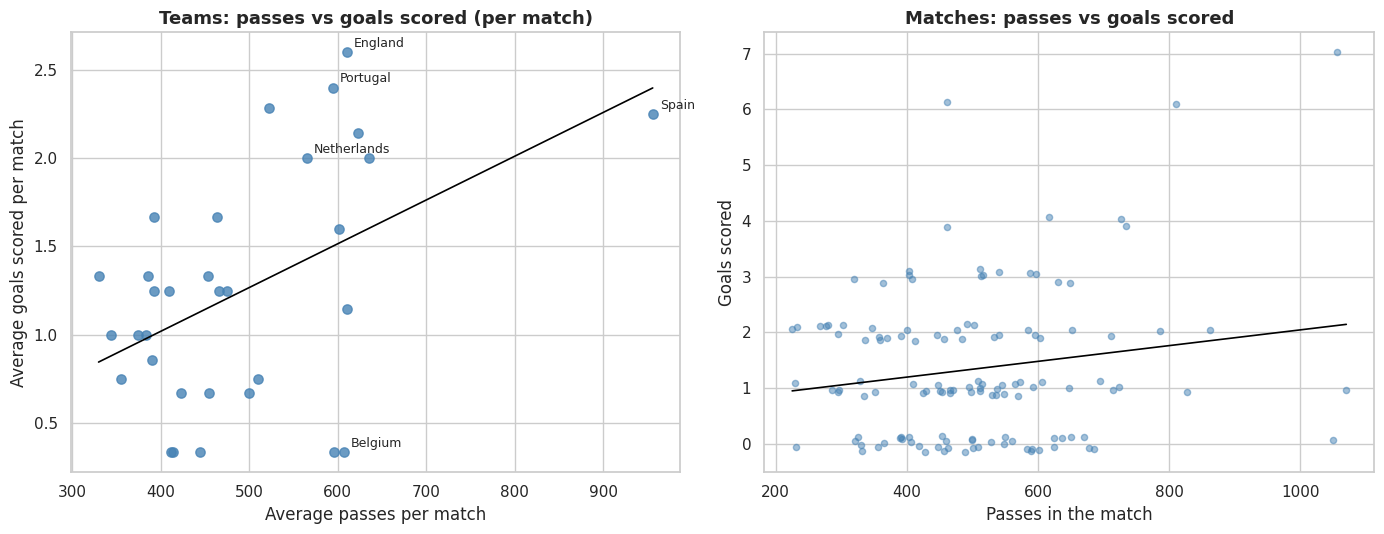

Team level (n=32):   Spearman rho = 0.35 (p = 0.049)
Match level (n=128): Spearman rho = 0.03 (p = 0.74)
Team level without Spain (n=31): rho = 0.29 (p = 0.108)
Team level, passes vs pass accuracy: rho = 0.95


,matches,passes,pass_accuracy,goals_for_pm
Team,,,,
Spain,4,955.75,92.23,2.25
Germany,3,635.33,88.93,2.00
Argentina,7,622.57,88.04,2.14
England,5,610.60,89.29,2.60
Croatia,7,610.57,87.88,1.14
Belgium,3,607.00,88.58,0.33


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: team level (32 teams, per-match averages)
sns.regplot(data=team_df, x="passes", y="goals_for_pm", scatter_kws={"s": 45, "color": "steelblue"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[0])
for team in ["Spain", "England", "Portugal", "Netherlands", "Belgium"]:
    axes[0].annotate(team, (team_df.loc[team, "passes"], team_df.loc[team, "goals_for_pm"]),
                     xytext=(5, 4), textcoords="offset points", fontsize=9)
axes[0].set(title="Teams: passes vs goals scored (per match)", xlabel="Average passes per match", ylabel="Average goals scored per match")

# Right: match level (128 team-matches)
sns.regplot(data=fifa_df, x="Passes", y="Goal", x_jitter=0, y_jitter=0.15, scatter_kws={"s": 20, "alpha": 0.5, "color": "steelblue"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[1])
axes[1].set(title="Matches: passes vs goals scored", xlabel="Passes in the match", ylabel="Goals scored")
plt.tight_layout()
plt.show()

rho_team, p_team = stats.spearmanr(team_df["passes"], team_df["goals_for_pm"])
rho_match, p_match = stats.spearmanr(fifa_df["Passes"], fifa_df["Goal"])
rho_acc, _ = stats.spearmanr(team_df["passes"], team_df["pass_accuracy"])
without_spain = team_df.drop(index="Spain")
rho_ns, p_ns = stats.spearmanr(without_spain["passes"], without_spain["goals_for_pm"])
print(f"Team level (n=32):   Spearman rho = {rho_team:.2f} (p = {p_team:.3f})")
print(f"Match level (n=128): Spearman rho = {rho_match:.2f} (p = {p_match:.2f})")
print(f"Team level without Spain (n=31): rho = {rho_ns:.2f} (p = {p_ns:.3f})")
print(f"Team level, passes vs pass accuracy: rho = {rho_acc:.2f}")
team_df.sort_values("passes", ascending=False)[["matches", "passes", "pass_accuracy", "goals_for_pm"]].head(6)

**What the data shows:** across teams, average passes and goals per match are moderately related (Spearman 0.35, p = 0.049), but the link is fragile: without Spain it falls to 0.29 (p = 0.108). Between individual matches there is no relationship (0.03, p = 0.74). Across teams, pass volume and pass accuracy are almost the same ranking (0.95): the heaviest passers (Spain 92.2% accuracy, Germany, Argentina, England) are also the most accurate. Belgium shows the counter-example: 607 passes per match but just 0.33 goals per match (1 goal in 3 matches).

**Interpretation:** style-heavy teams tend to be accurate, but passing more in a match did not go with scoring more. The modest team-level association mostly reflects a few strong sides (Spain, England) that were also good finishers, and it should not be read as passing volume driving goals.

### 5.6 Q5. Do line breaks turn into goals?
Line breaks (passes that bypass a defensive line) are a more direct measure of progression than raw pass counts.

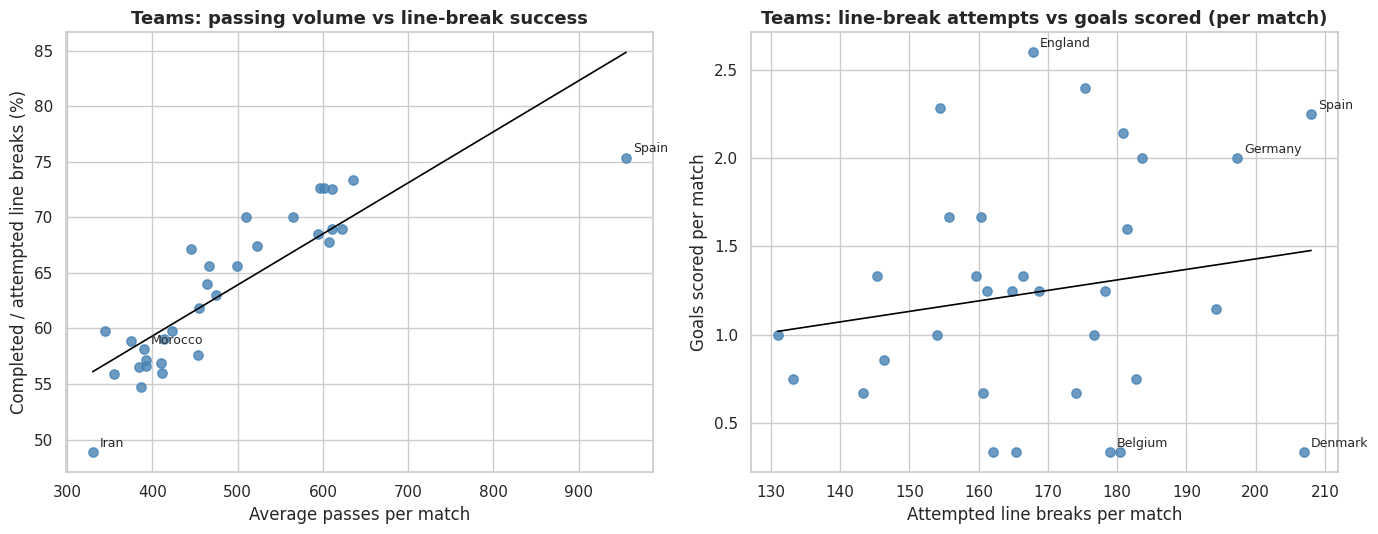

Team level (n=32): line-break attempts vs goals per match: rho = 0.11 (p = 0.54)
Match level: completed line breaks vs goals: rho = 0.03
Match level: line-break success vs pass accuracy: rho = 0.84


,matches,line_breaks,line_break_success,goals_for_pm
Team,,,,
Spain,4,208.00,75.36,2.25
Denmark,3,207.00,72.62,0.33
Germany,3,197.33,73.31,2.00
Croatia,7,194.29,68.97,1.14
Netherlands,5,183.60,70.04,2.00


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.regplot(data=team_df, x="passes", y="line_break_success", scatter_kws={"s": 45, "color": "steelblue"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[0])
for team in ["Spain", "Iran", "Morocco"]:
    axes[0].annotate(team, (team_df.loc[team, "passes"], team_df.loc[team, "line_break_success"]),
                     xytext=(5, 4), textcoords="offset points", fontsize=9)
axes[0].set(title="Teams: passing volume vs line-break success", xlabel="Average passes per match",
            ylabel="Completed / attempted line breaks (%)")

sns.regplot(data=team_df, x="line_breaks", y="goals_for_pm", scatter_kws={"s": 45, "color": "steelblue"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[1])
for team in ["Spain", "Denmark", "Germany", "Belgium", "England"]:
    axes[1].annotate(team, (team_df.loc[team, "line_breaks"], team_df.loc[team, "goals_for_pm"]),
                     xytext=(5, 4), textcoords="offset points", fontsize=9)
axes[1].set(title="Teams: line-break attempts vs goals scored (per match)", xlabel="Attempted line breaks per match",
            ylabel="Goals scored per match")
plt.tight_layout()
plt.show()

rho_team, p_team = stats.spearmanr(team_df["line_breaks"], team_df["goals_for_pm"])
rho_lb, _ = stats.spearmanr(fifa_df["Completed Line Breaks"], fifa_df["Goal"])
rho_lb_acc, _ = stats.spearmanr(fifa_df["Line Break Success (%)"], fifa_df["Pass Accuracy (%)"])
print(f"Team level (n=32): line-break attempts vs goals per match: rho = {rho_team:.2f} (p = {p_team:.2f})")
print(f"Match level: completed line breaks vs goals: rho = {rho_lb:.2f}")
print(f"Match level: line-break success vs pass accuracy: rho = {rho_lb_acc:.2f}")
team_df.sort_values("line_breaks", ascending=False)[["matches", "line_breaks", "line_break_success", "goals_for_pm"]].head(5)

**What the data shows:** across teams, line-break success climbs steeply with passing volume: Spain completed 75.4% of its attempts, while Iran completed only 48.9%. Success also tracks pass accuracy match by match (ρ = 0.84). More attempts do not go with more goals: at team level the correlation between line-break attempts and goals per match is 0.11 (p = 0.54), and between completed line breaks and goals at match level it is 0.03. Denmark attempted 207 line breaks per match (second only to Spain's 208) yet scored one goal in three matches, whereas Spain and Germany, with similar volumes, scored 2.25 and 2.00 per match.

**Interpretation:** line-break success is largely another face of ball security (accuracy), not an independent driver of scoring. **Caveat:** the file does not define line breaks, so attempts may count the same passes that appear in the pass totals.

### 5.7 Q6. Shot volume, shot quality and finishing
Which teams scored more or fewer goals than their shot volume suggests, and how do goals scale with shots on target?

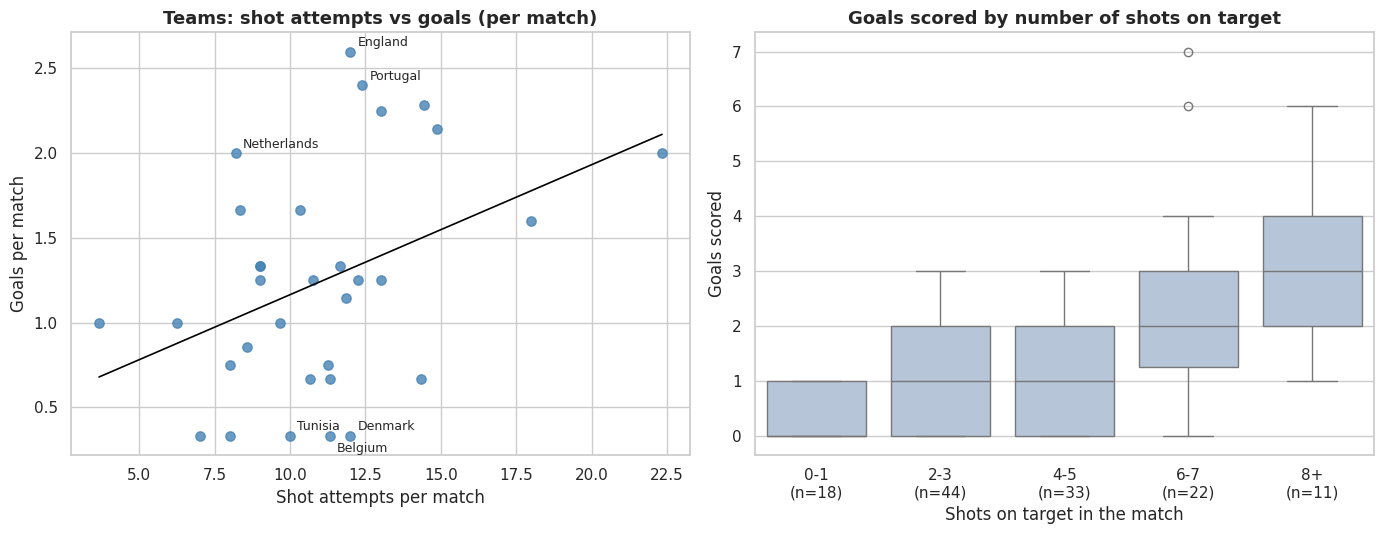

Team level (n=32): Pearson r = 0.40 (p = 0.022); each extra shot per match ~ 0.08 extra goals per match
Overall: 172 goals from 1441 attempts (11.9%); on-target attempts: 513
Spearman, goals vs on-target shots (match level): 0.56; vs total attempts: 0.30

Most above / below the shots-to-goals line (3-5 matches each, so treat with care):


,matches,shots,goals_for_pm,goals_vs_shots
Team,,,,
England,5,12.00,2.60,1.28
Portugal,5,12.40,2.40,1.05
Netherlands,5,8.20,2.00,0.97
Tunisia,3,10.00,0.33,-0.83
Belgium,3,11.33,0.33,-0.93
Denmark,3,12.00,0.33,-0.99


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

slope, intercept = np.polyfit(team_df["shots"], team_df["goals_for_pm"], 1)
team_df["goals_vs_shots"] = team_df["goals_for_pm"] - (slope * team_df["shots"] + intercept)

sns.regplot(data=team_df, x="shots", y="goals_for_pm", scatter_kws={"s": 45, "color": "steelblue"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[0])
extremes = pd.concat([team_df["goals_vs_shots"].nlargest(3), team_df["goals_vs_shots"].nsmallest(3)]).index
for i, team in enumerate(extremes):
    offset = (5, 4) if i < 3 or i % 2 else (5, -12)          # stagger the labels of the crowded bottom row
    axes[0].annotate(team, (team_df.loc[team, "shots"], team_df.loc[team, "goals_for_pm"]),
                     xytext=offset, textcoords="offset points", fontsize=9)
axes[0].set(title="Teams: shot attempts vs goals (per match)", xlabel="Shot attempts per match", ylabel="Goals per match")

target_bins = pd.cut(fifa_df["On Target"], bins=[-1, 1, 3, 5, 7, 20], labels=["0-1", "2-3", "4-5", "6-7", "8+"])
bin_sizes = target_bins.value_counts()
sns.boxplot(x=target_bins, y=fifa_df["Goal"], color="lightsteelblue", ax=axes[1])
axes[1].set_xticks(range(len(bin_sizes)), [f"{b}\n(n={bin_sizes[b]})" for b in target_bins.cat.categories])
axes[1].set(title="Goals scored by number of shots on target", xlabel="Shots on target in the match", ylabel="Goals scored")
plt.tight_layout()
plt.show()

r, p = stats.pearsonr(team_df["shots"], team_df["goals_for_pm"])
print(f"Team level (n=32): Pearson r = {r:.2f} (p = {p:.3f}); each extra shot per match ~ {slope:.2f} extra goals per match")
print(f"Overall: {fifa_df['Goal'].sum()} goals from {fifa_df['Total Attempts'].sum()} attempts "
      f"({fifa_df['Goal'].sum() / fifa_df['Total Attempts'].sum():.1%}); on-target attempts: {fifa_df['On Target'].sum()}")
print(f"Spearman, goals vs on-target shots (match level): {stats.spearmanr(fifa_df['On Target'], fifa_df['Goal'])[0]:.2f}; "
      f"vs total attempts: {stats.spearmanr(fifa_df['Total Attempts'], fifa_df['Goal'])[0]:.2f}")
print("\nMost above / below the shots-to-goals line (3-5 matches each, so treat with care):")
team_df.loc[extremes, ["matches", "shots", "goals_for_pm", "goals_vs_shots"]].sort_values("goals_vs_shots", ascending=False)

**What the data shows:** teams scored 172 goals from 1,441 attempts (11.9%) and 513 on-target attempts, so roughly one on-target attempt in three ended in a goal. Across teams, each additional attempt per match goes with about 0.08 more goals per match (Pearson r = 0.40, p = 0.022). At match level, goals track shots on target (ρ = 0.56) far more than total attempts (0.30), and the right-hand chart shows the median rising from 0 goals with 0 to 1 shots on target to 3 goals with 8 or more. England (+1.28 goals per match above the line), Portugal (+1.05) and the Netherlands (+0.97, on only 8.2 attempts per match) scored well beyond their shot volume; Denmark (-0.99), Belgium (-0.93) and Tunisia (-0.83) fell short.

**Interpretation:** what mattered was getting shots on target rather than shooting often, and clinical finishing separated the best attacks. **Caveat:** goals are a subset of on-target shots, so part of that relationship is mechanical, and 3 to 5 matches per team is too few to separate finishing skill from luck (over- and under-performance here is descriptive).

### 5.8 Q7. Discipline: who was booked most, and what goes with it?

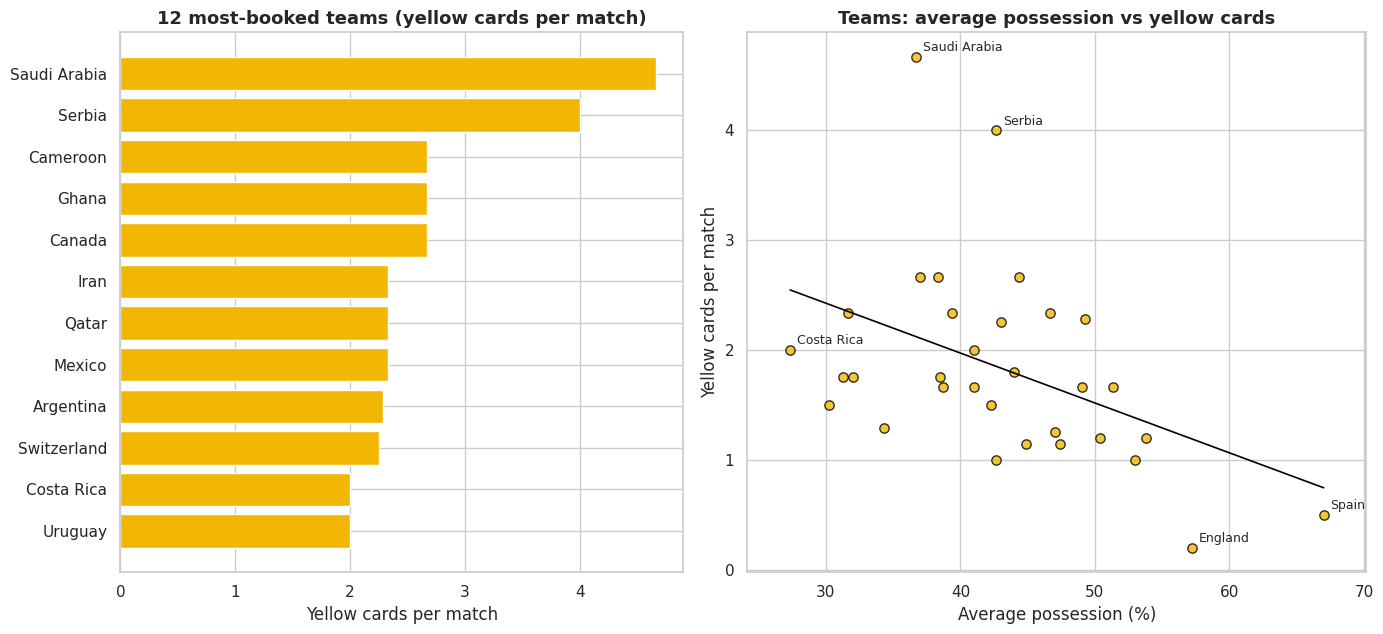

Tournament totals: 221 yellow cards, 3 red cards
Red cards: [['Wales', 'Iran', 'Group stage'], ['Cameroon', 'Brazil', 'Group stage'], ['Morocco', 'Portugal', 'Quarter-final']]
Match level: Fouls Against vs Yellow Cards: rho = 0.43 (p = 0.0000)
Match level: Possession (%) vs Yellow Cards: rho = -0.34 (p = 0.0001)
Team level (n=32): possession vs yellow cards: rho = -0.49 (p = 0.004)

Yellow cards per team-match by result:
Result
Win    1.53
Draw   1.77
Loss   1.90


,matches,yellow_cards,fouls,possession
Team,,,,
Saudi Arabia,3,4.67,18.67,36.67
Serbia,3,4.00,14.33,42.67
Canada,3,2.67,11.00,44.33
Cameroon,3,2.67,10.67,38.33
Ghana,3,2.67,15.33,37.00


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})

cards = team_df.sort_values("yellow_cards").tail(12)
axes[0].barh(cards.index, cards["yellow_cards"], color="#f2b705")
axes[0].set(title="12 most-booked teams (yellow cards per match)", xlabel="Yellow cards per match")

sns.regplot(data=team_df, x="possession", y="yellow_cards", scatter_kws={"s": 45, "color": "#f2b705", "edgecolor": "black"},
            line_kws={"color": "black", "lw": 1.2}, ci=None, ax=axes[1])
for team in ["Saudi Arabia", "Serbia", "England", "Spain", "Costa Rica"]:
    axes[1].annotate(team, (team_df.loc[team, "possession"], team_df.loc[team, "yellow_cards"]),
                     xytext=(5, 4), textcoords="offset points", fontsize=9)
axes[1].margins(x=0.08)
axes[1].set(title="Teams: average possession vs yellow cards", xlabel="Average possession (%)", ylabel="Yellow cards per match")
plt.tight_layout()
plt.show()

print(f"Tournament totals: {fifa_df['Yellow Cards'].sum()} yellow cards, {fifa_df['Red Cards'].sum()} red cards")
print("Red cards:", fifa_df.loc[fifa_df["Red Cards"] > 0, ["Team", "Against", "Stage"]].values.tolist())
for a, b in [("Fouls Against", "Yellow Cards"), ("Possession (%)", "Yellow Cards")]:
    rho, p = stats.spearmanr(fifa_df[a], fifa_df[b])
    print(f"Match level: {a} vs {b}: rho = {rho:.2f} (p = {p:.4f})")
rho, p = stats.spearmanr(team_df["possession"], team_df["yellow_cards"])
print(f"Team level (n=32): possession vs yellow cards: rho = {rho:.2f} (p = {p:.3f})")
print("\nYellow cards per team-match by result:")
print(fifa_df.groupby("Result")["Yellow Cards"].mean().round(2).loc[["Win", "Draw", "Loss"]].to_string())
team_df.sort_values("yellow_cards", ascending=False)[["matches", "yellow_cards", "fouls", "possession"]].head(5)

**What the data shows:** the tournament had 221 yellow cards and only 3 red cards (Wales v Iran, Cameroon v Brazil, Morocco v Portugal). Fouls and yellow cards move together (ρ = 0.43), and possession moves against cards: -0.34 across matches and -0.49 across teams (p = 0.004). Losing teams were booked more (1.90 per match) than winners (1.53), with draws in between (1.77). Saudi Arabia and Serbia stand well above the rest (4.67 and 4.00 per match), while the low-possession side Costa Rica sits near the middle (2.00), so low possession alone does not explain it.

**Interpretation:** teams that spent more time without the ball were booked more, consistent with more defending and tackling; that is an association only. The column `Fouls Against` is ambiguous in the file (fouls committed or suffered), but its positive link with a team's own cards suggests fouls committed. **Caveat:** cards are also shaped by referee, opponent and game state, and the 3-match samples for 16 teams are small.

## 6. Statistical Analysis

### 6.1 Z-normalisation within teams
The question so far has been how teams compare. The next question is how *matches* compare within a team.

**What it does:** z-normalisation rescales each value by its group's average and spread: `z = (x - team mean) / team standard deviation`. Here the group is the team, so each match is compared with the same team's other matches.

**Why it is useful here:** raw counts reflect team style (Spain averaged 956 passes, Iran 330), so a raw 600 is unremarkable for one and huge for the other. A z-score removes the team's baseline and asks how unusual this match was *for that team*.

**How to read it:** a positive z means more than the team's own average (+1.5 = one and a half standard deviations above it), a negative z means fewer, and 0 is a typical match. It is applied to `Passes`, `Passes Completed`, `Attempted Line Breaks` and `Completed Line Breaks`.

**Improvements over the original implementation** (the numbers are unchanged, which is asserted in the code):

- The inline `lambda` is now the named function `z_normalization(group, cols_to_perform)` the exercise asked for, applied with `apply()`.
- Columns are selected before `apply()`, which removes the pandas `DeprecationWarning` about operating on the grouping column, and `group_keys=False` keeps the original row index so the scores can be joined back to the data (the original result was a separate frame indexed by team).
- A group with zero spread returns `NaN` instead of dividing by zero, and the result is verified (mean 0, standard deviation 1 within every team).

In [21]:
z_cols = ["Passes", "Passes Completed", "Attempted Line Breaks", "Completed Line Breaks"]


def z_normalization(group, cols_to_perform):
    """Z-normalise the given columns inside one group: (value - group mean) / group standard deviation.

    Uses the sample standard deviation (pandas default, ddof=1). A column with zero spread in the group
    returns NaN instead of dividing by zero.
    """
    values = group[cols_to_perform]
    std = values.std().replace(0, np.nan)
    return (values - values.mean()) / std


# Selecting the columns before apply() keeps the "Team" grouping column out of the calculation
# (the original version triggered a pandas DeprecationWarning here), and group_keys=False keeps the original row index.
z_scores = fifa_df.groupby("Team", group_keys=False)[z_cols].apply(z_normalization, cols_to_perform=z_cols)
z_scores = z_scores.add_suffix(" (z)")
fifa_df = fifa_df.drop(columns=z_scores.columns, errors="ignore").join(z_scores)   # drop first so the cell can be re-run

# Verification: within every team each z-scored column has mean 0 and standard deviation 1
check = z_scores.groupby(fifa_df["Team"]).agg(["mean", "std"])
assert np.allclose(check.xs("mean", axis=1, level=1), 0) and np.allclose(check.xs("std", axis=1, level=1), 1)
print("z-scores verified: mean 0 and standard deviation 1 within all 32 teams; NaN count:", int(z_scores.isna().sum().sum()))

# Regression check: the refactored function reproduces the original inline calculation exactly
original_calc = fifa_df.groupby("Team")[z_cols].apply(lambda g: (g - g.mean()) / g.std()).reset_index(level=0, drop=True)
assert np.allclose(original_calc.sort_index().to_numpy(), fifa_df[z_scores.columns].to_numpy())
print("Result identical to the original lambda-based calculation.")

# A z-score in a team with n matches cannot exceed (n - 1) / sqrt(n) in size
bound = pd.DataFrame({"Teams": team_df["matches"].value_counts().sort_index()})
bound["Largest possible |z|"] = (bound.index - 1) / np.sqrt(bound.index)
bound.index.name = "Matches played"
bound

z-scores verified: mean 0 and standard deviation 1 within all 32 teams; NaN count: 0
Result identical to the original lambda-based calculation.


,Teams,Largest possible |z|
Matches played,,
3,16,1.15
4,8,1.50
5,4,1.79
7,4,2.27


**Two limits of z-scores here:** each team has only 3 to 7 matches, so the standard deviation is itself noisy, and a z-score cannot exceed (n-1)/√n in size (1.15 for a 3-match team, 2.27 for a 7-match team), so the size of a z-score cannot be compared across teams with different match counts. And because every team's z-scores average to zero by construction, they say nothing about which team passes more overall. That is what the earlier team-level analysis is for.

### 6.2 Which matches were unusual for the team that played them?

In [22]:
extreme_cols = ["Match No.", "Stage", "Team", "Against", "Goal", "Goals Against", "Passes", "Passes (z)"]
fifa_df["Team average passes"] = fifa_df.groupby("Team")["Passes"].transform("mean")

print("Highest and lowest passing volume relative to the team's own norm:")
display(pd.concat([fifa_df.nlargest(5, "Passes (z)"), fifa_df.nsmallest(5, "Passes (z)")])
        [extreme_cols + ["Team average passes"]].round(2))

z_only = [f"{c} (z)" for c in z_cols]
flag = (fifa_df[z_only].abs() > 1.5)
print(f"Team-matches with at least one |z| > 1.5: {flag.any(axis=1).sum()} of {len(fifa_df)}")
print(flag.sum().to_string())

# Line-break extremes
print("\nLargest / smallest line-break z-scores:")
display(pd.concat([fifa_df.nlargest(3, "Attempted Line Breaks (z)"), fifa_df.nsmallest(3, "Completed Line Breaks (z)")])
        [["Match No.", "Stage", "Team", "Against", "Attempted Line Breaks", "Completed Line Breaks",
          "Attempted Line Breaks (z)", "Completed Line Breaks (z)"]].round(2))

Highest and lowest passing volume relative to the team's own norm:


,Match No.,Stage,Team,Against,Goal,Goals Against,Passes,Passes (z),Team average passes
2,2,Group stage,England,Iran,6,2,810,1.71,610.60
77,39,Group stage,Argentina,Poland,2,0,862,1.69,622.57
123,62,Semi-final,Morocco,France,0,2,583,1.66,389.86
113,57,Quarter-final,Brazil,Croatia,1,1,695,1.61,601.80
14,8,Group stage,France,Australia,4,1,734,1.57,522.29
110,56,Round of 16,Portugal,Switzerland,6,1,461,-1.65,594.20
120,61,Semi-final,Argentina,Croatia,3,0,408,-1.51,622.57
54,28,Group stage,Spain,Germany,1,1,647,-1.50,955.75
93,47,Group stage,Switzerland,Serbia,3,2,403,-1.47,475.00
52,27,Group stage,Croatia,Canada,4,1,461,-1.44,610.57


Team-matches with at least one |z| > 1.5: 13 of 128
Passes (z)                   7
Passes Completed (z)         8
Attempted Line Breaks (z)    5
Completed Line Breaks (z)    6

Largest / smallest line-break z-scores:


,Match No.,Stage,Team,Against,Attempted Line Breaks,Completed Line Breaks,Attempted Line Breaks (z),Completed Line Breaks (z)
126,64,Final,Argentina,France,249,172,1.76,1.81
28,15,Group stage,Portugal,Ghana,197,150,1.66,1.56
104,53,Round of 16,Japan,Croatia,253,137,1.38,1.27
116,59,Quarter-final,Morocco,Portugal,128,63,-1.72,-1.98
52,27,Group stage,Croatia,Canada,97,55,-1.79,-1.84
39,20,Group stage,United States,England,143,88,-1.44,-1.46


**What the data shows**

- **Relative is not the same as raw.** Spain's 647 passes against Germany was above the tournament's 75th percentile (590 passes), yet it was Spain's lowest count and sits 1.5 standard deviations below the team's average (956). Conversely, Morocco's 583 passes in the semi-final against France is only mildly above the tournament median (496) but is 1.66 standard deviations above Morocco's own average of 390, their busiest match, in a 0-2 loss.
- **High passing relative to the team's norm:** England v Iran (810 vs an average of 611, z = +1.71) and Argentina v Poland (862 vs 623, +1.69).
- **Low passing relative to the norm:** Portugal v Switzerland (461 vs 594, z = -1.65, a 6-1 win) and Argentina v Croatia in the semi-final (408 vs 623, -1.51, a 3-0 win).
- **Line breaks:** in the final, Argentina attempted 249 (z = +1.76) and completed 172 (+1.81), the most of their tournament, while Morocco's 63 completed line breaks in the quarter-final against Portugal (-1.98) were their fewest (they won 1-0).
- Only 13 of 128 team-matches have any |z| above 1.5, which is expected given how few matches each team has.

**Interpretation:** several of the most one-sided wins came with *less* passing than the team's norm, which sets up the question in section 6.4 of whether "passing more than usual" goes with better results.

### 6.3 The two finalists, match by match

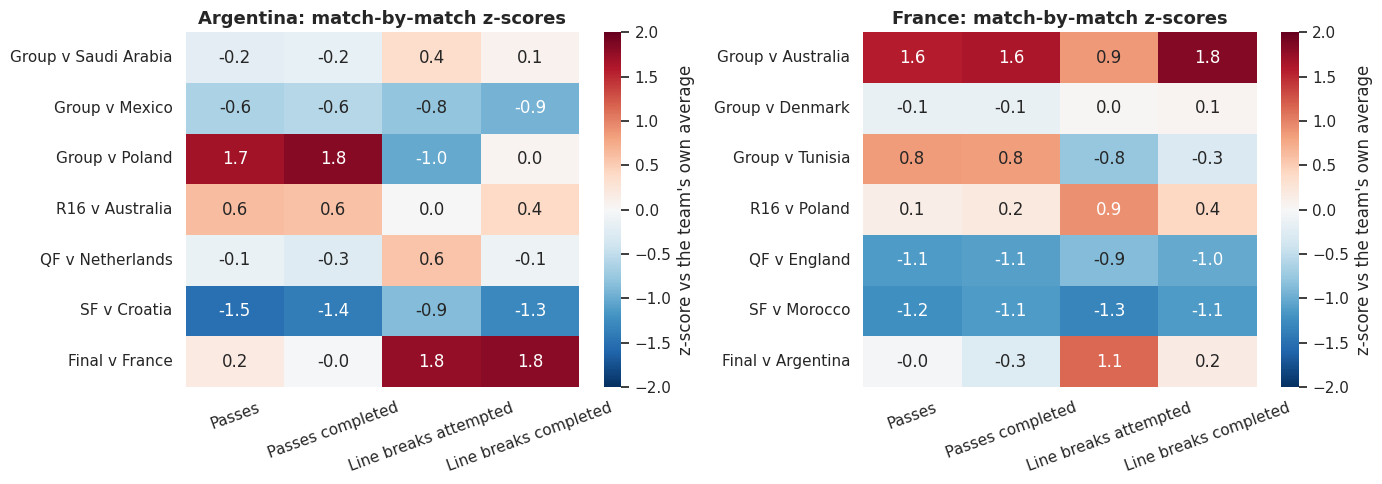

In [23]:
finalists = fifa_df.loc[fifa_df["Match No."] == 64, "Team"].tolist()
stage_short = {"Group stage": "Group", "Round of 16": "R16", "Quarter-final": "QF", "Semi-final": "SF",
               "Third place": "3rd", "Final": "Final"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, team in zip(axes, finalists):
    rows = fifa_df[fifa_df["Team"] == team].sort_values("Match No.")
    heat = rows.set_index(rows["Stage"].map(stage_short) + " v " + rows["Against"])[z_only]
    heat.columns = ["Passes", "Passes completed", "Line breaks attempted", "Line breaks completed"]
    sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
                cbar_kws={"label": "z-score vs the team's own average"}, ax=ax)
    ax.set(title=f"{team}: match-by-match z-scores", ylabel="")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**What the data shows:** Argentina's busiest passing match was the group win over Poland (+1.7), yet they attempted fewer line breaks than usual there (-1.0); in the final the pattern reversed (passes typical at +0.2, line breaks attempted and completed both +1.8). France's most active match was the group game against Australia (+1.6 passes, +1.8 completed line breaks). Both finalists won their semi-finals while passing and line-breaking well below their own norms (Argentina -1.5 passes against Croatia; France -1.2 against Morocco), and France was similarly below its norm in the quarter-final against England (-1.1).

**Interpretation:** the two finalists did not follow a single game pattern, and winning did not require their highest passing volume. Rather than a fixed style, the data show teams adapting match by match.

### 6.4 Do relationships hold *within* a team?
Two checks: whether raw correlations between the four metrics are inflated by differences between teams, and whether matches in which a team passes or line-breaks more than usual also bring better results than usual.

In [24]:
# Within-team goal and goal-difference z-scores, using the same function
outcome_cols = ["Goal", "Goal Difference"]
outcome_z = fifa_df.groupby("Team", group_keys=False)[outcome_cols].apply(z_normalization, cols_to_perform=outcome_cols)
fifa_df["Goal (z)"] = outcome_z["Goal"]
fifa_df["Goal Difference (z)"] = outcome_z["Goal Difference"]

# 1. Raw pooled correlation vs within-team (z-score) correlation
raw_corr = fifa_df[z_cols].corr(method="spearman")
z_corr = fifa_df[z_only].corr(method="spearman")
compare = pd.DataFrame({
    "Raw (all teams pooled)": [raw_corr.loc["Passes", "Attempted Line Breaks"], raw_corr.loc["Passes", "Completed Line Breaks"],
                               raw_corr.loc["Attempted Line Breaks", "Completed Line Breaks"]],
    "Within-team (z-scores)": [z_corr.loc["Passes (z)", "Attempted Line Breaks (z)"], z_corr.loc["Passes (z)", "Completed Line Breaks (z)"],
                               z_corr.loc["Attempted Line Breaks (z)", "Completed Line Breaks (z)"]],
}, index=["Passes vs attempted line breaks", "Passes vs completed line breaks", "Attempted vs completed line breaks"])
display(compare.round(2))

# 2. Do matches where a team passes or breaks lines more than usual also bring better results than usual?
no_shootout = ~fifa_df["Went to Shoot-out"]
rows = []
for metric in ["Passes (z)", "Attempted Line Breaks (z)", "Completed Line Breaks (z)"]:
    for outcome in ["Goal (z)", "Goal Difference (z)"]:
        for label, mask in [("all matches", slice(None)), ("excluding shoot-out matches", no_shootout)]:
            pair = fifa_df.loc[mask, [metric, outcome]].dropna()
            rho, p = stats.spearmanr(pair[metric], pair[outcome])
            rows.append({"Metric": metric, "Outcome": outcome, "Sample": label, "n": len(pair), "rho": rho, "p-value": p})
pd.DataFrame(rows).round(3)

,Raw (all teams pooled),Within-team (z-scores)
Passes vs attempted line breaks,0.59,0.43
Passes vs completed line breaks,0.81,0.58
Attempted vs completed line breaks,0.85,0.79


,Metric,Outcome,Sample,n,rho,p-value
0,Passes (z),Goal (z),all matches,124,-0.13,0.15
1,Passes (z),Goal (z),excluding shoot-out matches,114,-0.14,0.13
2,Passes (z),Goal Difference (z),all matches,125,-0.23,0.01
3,Passes (z),Goal Difference (z),excluding shoot-out matches,115,-0.22,0.02
4,Attempted Line Breaks (z),Goal (z),all matches,124,0.01,0.89
5,Attempted Line Breaks (z),Goal (z),excluding shoot-out matches,114,0.01,0.96
6,Attempted Line Breaks (z),Goal Difference (z),all matches,125,0.00,1.00
7,Attempted Line Breaks (z),Goal Difference (z),excluding shoot-out matches,115,0.06,0.56
8,Completed Line Breaks (z),Goal (z),all matches,124,-0.01,0.90
9,Completed Line Breaks (z),Goal (z),excluding shoot-out matches,114,-0.04,0.69


**What the data shows**

- **Raw correlations overstate the within-team link.** Passes and completed line breaks correlate at 0.81 across all teams pooled but 0.58 within teams; passes and attempted line breaks 0.59 vs 0.43; attempted and completed line breaks 0.85 vs 0.79. Part of the raw association reflects team style (possession-based teams both pass and break lines more), not match-to-match variation.
- **No evidence that passing or line-breaking more than usual improves results.** Line-break z-scores show essentially zero correlation with goals or goal difference (|ρ| ≤ 0.06). Passes show a weak negative relationship with goal difference (ρ = -0.23, p = 0.01; -0.22 without shoot-out matches), and none with goals (-0.13, p = 0.15).

**Interpretation:** the weak negative link is consistent with teams passing more when they trail or face a deep defence, but that is a guess. Twelve tests were run (threshold about 0.004 after Bonferroni correction), so none of these p-values clears the corrected bar; the passes-goal-difference result is a hint, not a finding. **Limitation:** goals and goal difference of teams with no variation (for example Australia, who scored exactly one goal in each of their four matches) cannot be z-scored, so a few rows drop out (n = 124 and 125).

### 6.5 What separates the winner from the loser of the same match?
Comparing the two sides of the same match removes the effect of the opponent and the match conditions. Only the 49 matches decided on goals are used; each metric is compared as winner minus loser with a paired Wilcoxon test and a rank-biserial effect size.

Decisive matches (settled on goals): 49 of 64


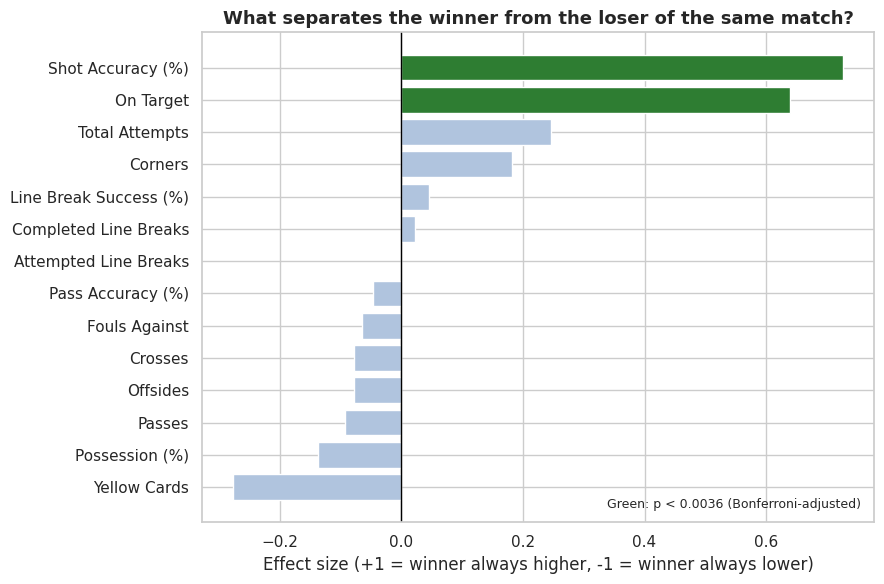

,Matches,Median winner - loser,Winner higher (%),Winner lower (%),Effect size,p-value,Significant
Metric,,,,,,,
Shot Accuracy (%),48,13.02,75.00,22.92,0.73,1.4e-05,True
On Target,49,2.00,65.31,22.45,0.64,2.5e-04,True
Total Attempts,49,2.00,61.22,34.69,0.25,1.4e-01,False
Corners,49,1.00,51.02,38.78,0.18,2.9e-01,False
Line Break Success (%),49,0.00,48.98,48.98,0.05,7.8e-01,False
Completed Line Breaks,49,0.00,48.98,48.98,0.02,8.9e-01,False
Attempted Line Breaks,49,-1.00,44.90,51.02,0.00,1.0e+00,False
Pass Accuracy (%),49,-0.12,48.98,51.02,-0.05,7.8e-01,False
Fouls Against,49,0.00,44.90,44.90,-0.06,7.1e-01,False


In [25]:
comparison_metrics = ["Shot Accuracy (%)", "On Target", "Total Attempts", "Corners", "Line Break Success (%)",
                      "Completed Line Breaks", "Attempted Line Breaks", "Pass Accuracy (%)", "Fouls Against", "Crosses",
                      "Offsides", "Passes", "Possession (%)", "Yellow Cards"]

decisive = fifa_df[fifa_df["Result"] != "Draw"]
winners = decisive[decisive["Result"] == "Win"].set_index("Match No.")
losers = decisive[decisive["Result"] == "Loss"].set_index("Match No.").loc[winners.index]
print(f"Decisive matches (settled on goals): {len(winners)} of {fifa_df['Match No.'].nunique()}")

rows = []
for metric in comparison_metrics:
    diff = (winners[metric] - losers[metric]).dropna()          # winner minus loser, one value per match
    nonzero = diff[diff != 0]
    ranks = stats.rankdata(nonzero.abs())
    # matched-pairs rank-biserial correlation: +1 = winner always higher, -1 = winner always lower
    effect = (ranks[(nonzero > 0).to_numpy()].sum() - ranks[(nonzero < 0).to_numpy()].sum()) / ranks.sum()
    rows.append({"Metric": metric, "Matches": len(diff), "Median winner - loser": diff.median(),
                 "Winner higher (%)": (diff > 0).mean() * 100, "Winner lower (%)": (diff < 0).mean() * 100,
                 "Effect size": effect, "p-value": stats.wilcoxon(diff).pvalue})
paired = pd.DataFrame(rows).set_index("Metric").sort_values("Effect size")

alpha = 0.05 / len(comparison_metrics)                            # Bonferroni threshold for 14 tests
paired["Significant"] = paired["p-value"] < alpha
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(paired.index, paired["Effect size"], color=np.where(paired["Significant"], "#2e7d32", "lightsteelblue"))
ax.axvline(0, color="black", lw=1)
ax.set(title="What separates the winner from the loser of the same match?",
       xlabel="Effect size (+1 = winner always higher, -1 = winner always lower)")
ax.text(0.98, 0.03, f"Green: p < {alpha:.4f} (Bonferroni-adjusted)", transform=ax.transAxes, ha="right", fontsize=9)
plt.tight_layout()
plt.show()

paired.sort_values("Effect size", ascending=False).style.format(precision=2, formatter={"p-value": "{:.1e}"})

**What the data shows:** only two metrics separate winners from losers convincingly after correcting for 14 comparisons (threshold p < 0.0036): **shot accuracy** (winners higher in 75% of matches, median +13 percentage points, effect size 0.73) and **shots on target** (higher in 65% of matches and lower in 22%, median +2, effect 0.64). Total attempts (61% higher vs 35% lower; effect 0.25, p = 0.14) and corners lean towards winners but not reliably. Possession (effect -0.14), passes (-0.09), pass accuracy and line-break metrics show nothing: the winner had less possession in 51% of matches and more in 45%, and a median of 14 fewer passes.

**Interpretation:** in this tournament, matches were separated by what teams did with the ball in the final third, not by how much of it they had. **Limitations:** shot accuracy and on-target shots are partly mechanical (a goal is an on-target shot), and with 49 matches the tests can only detect fairly large differences: the absence of an effect for possession is not proof that none exists. Yellow cards lean towards losers (effect -0.28, p = 0.13) but not reliably.

## 7. Key Findings

1. **Scoring followed shot quality, not style.** Goals correlate with shots on target (ρ = 0.56) and weakly with attempts (0.30); possession, passing, pass accuracy and line breaks all have |ρ| ≤ 0.11 with goals across matches.
2. **Possession did not predict results.** Winners averaged 42.4% possession against 44.6% for losers (ρ with goal difference = 0.03), and teams with 60% or more won 4, lost 4 and drew 1.
3. **Only shooting separated winners from losers.** In the 49 decided matches, shot accuracy and shots on target were the only metrics to survive multiple-testing correction; passing, possession and line-break metrics did not.
4. **Passing volume is a team trait, not a match-winning lever.** Teams that pass more are much more accurate (ρ = 0.95) and complete more line breaks, and the team-level link between passing and goals is modest and fragile (0.35, falling to 0.29 without Spain). Between matches it is absent (0.03).
5. **Line-break attempts did not convert into goals.** Team-level correlation with goals is 0.11; Denmark attempted 207 per match and scored one goal in three matches. Line-break success is largely pass accuracy under another name (0.84).
6. **England, Portugal and the Netherlands outscored their shot volume; Denmark, Belgium and Tunisia fell short.** With 3 to 5 matches this is descriptive only.
7. **Discipline separated qualifiers from eliminated teams.** Qualifiers were booked about half as often in the group stage (1.21 vs 2.27 yellow cards per match, the only qualifier-vs-eliminated difference that survives correction), and lower-possession teams were booked more (ρ = -0.49 across teams).
8. **Group standings reconcile exactly with the data.** Ranking on points, goal difference and goals scored reproduces all 16 qualifiers; 4 points was enough for only 3 of the 10 teams that finished on it.
9. **Within-team normalisation changes the picture.** A z-score shows a match as unusual for its team even when the raw number is unremarkable (Spain's 647 passes; Morocco's 583), and raw pooled correlations between passing and line-breaking (0.59 to 0.85) shrink within teams (0.43 to 0.79), so part of them was team style.
10. **Data quality mattered.** A misspelt opponent, a wrong points value (Wales), shoot-out points mixed into `Pts`, and an extreme `Receptions D` value would each have distorted results if not caught.

## 8. Conclusion

Across the 2022 World Cup, the statistics that go with success were about efficiency and discipline rather than control. Teams with the ball more, or that passed and line-broke more, were no more likely to win; the sides that got shots on target, converted them, and kept out of the referee's book progressed. Team style does exist and is strong (passing volume, accuracy and line-break success move together), but it is a property of the team rather than a lever that improved results match by match. Group-wise z-normalisation was the right tool to show this, because it separates a team's habitual style from how a particular match departed from it.

### Limitations
- **Small samples.** Teams played 3 to 7 matches, and 16 teams played exactly 3, so team-level rates and within-team z-scores are volatile.
- **Association, not causation.** Only final match totals are available: game state (leading or trailing), lineups, injuries and refereeing are not recorded.
- **Extra time and definitions.** Five matches include extra time, and several columns (line breaks, `Fouls Against`, possession) are not defined in the file.
- **Multiple comparisons.** Many tests were run; where it mattered a Bonferroni threshold is reported, and unadjusted p-values should be read as hints.

### Next steps
- Add a per-90-minute normalisation (or exclude extra-time matches) to remove the extra-time distortion.
- Model match outcome (for example logistic regression on shot and possession differences) and evaluate it out of sample.
- Bring in a second tournament, which would give many more matches per team and allow a proper test of the team-style findings.